In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
%cd /content/drive/MyDrive/

In [ ]:
# 필요한 패키지 설치
!pip install -q adapter-transformers
!pip install -q --upgrade transformers accelerate
!pip install -q --upgrade transformers
!pip install -q peft==0.6.0
!pip install -q ipywidgets
!pip install -q datasets

# Library

In [ ]:
# 데이터 전처리
import pandas as pd
import numpy as np
import os
import json
import time

from tqdm import tqdm
tqdm.pandas()

# 데이터 전처리
import re

# 이미지 업로드
import requests
from PIL import Image, ImageOps
from io import BytesIO

# 파이토치, 허깅페이스
import torch
import transformers
from transformers import GenerationConfig
# from datasets import load_dataset

# image-LLM 후보군
from transformers import LlavaNextProcessor, LlavaNextForConditionalGeneration
from transformers import GenerationConfig,  AutoModelForCausalLM, AutoTokenizer

# 평가지표
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Utils

In [ ]:
def extract_first_image_urls(images_list):
    # 비어있거나 잘못된 값 방지
    if not images_list or not isinstance(images_list, list) or len(images_list) == 0:
        return pd.Series([None, None, None])
    img = images_list[0]
    return pd.Series([
        img.get('small_image_url'),
        img.get('medium_image_url'),
        img.get('large_image_url')
    ])

In [ ]:
# Helper: URL에서 이미지 로드 & (336×336, 448×448)으로 리사이즈
# 1. 이미지 로딩 및 448x448 리사이즈 함수 (미스랄 LLaVA 기본 사이즈)
def load_and_preprocess_image_llava(url: str, idx=None, target_size=(448, 448)):
    try:
        response = requests.get(url, stream=True, timeout=180)
        if response.status_code == 200:
            img = Image.open(BytesIO(response.content)).convert("RGB")
            img = ImageOps.fit(img, target_size, Image.BICUBIC)
            return img
    except Exception as e:
        print(f"[{idx}] Error fetching image for LLaVA: {e}")
        # 1초 딜레이: 네트워크 차단 방지
        time.sleep(1)
    # 실패 시 검은색 placeholder 반환
    img = Image.fromarray(np.zeros((*target_size, 3), dtype=np.uint8), "RGB")
    return img

In [ ]:
# Build a conversation for one product (five fashion aspects)
def build_conversations_llava(df: pd.DataFrame) -> list[list[dict]]:
    """
    df는 적어도 두 컬럼 필요:
      - 'title_y': 제품 제목 (문자열)
      - 'medium_image_url': 이미지 URL (문자열)

    return: 각 행마다 LLaVANext에 들어갈 “conversation” 리스트를 생성합니다.
    """
    conversations = []

    for idx, row in tqdm(df.iterrows(), total=len(df)):
        title_text = row["title_y"]
        url = row["medium_image_url"]
        # 이미지 로드
        pil_img = load_and_preprocess_image_llava(url, idx=idx)
        # 지시문 구성
        text_instruction = (
            f"Product title: {title_text}\n\n"
            "Analyze the product image and product title to generate a profile, explicitly including the reasoning process as part of the output."
            "The reasoning should clearly explain how the visual elements support the derived profile. \n\n"
        )
        conversation = [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": text_instruction},
                    {"type": "image"}
                ],
                "_preprocessed_image": pil_img
            }
        ]
        conversations.append(conversation)
    return conversations

In [ ]:
# LLaVA 템플릿을 적용해 “완성된 프롬프트 문자열” 목록 생성
def apply_templates_llava(conversations: list[list[dict]], processor) -> list[str]:
    """
    conversations: build_conversations() 결과
    반환: 각 conversation마다 processor.apply_chat_template(...)을 거쳐
         LLaVANext에 필요한 전체 프롬프트 문자열을 반환합니다.
    """
    prompts = []
    for conv in conversations:
        # add_generation_prompt=True → 마지막에 “ASSISTANT:” 태그를 자동 부착
        p = processor.apply_chat_template(conv, add_generation_prompt=True)
        prompts.append(p)
    return prompts

In [ ]:
# 응답에서 ASSISTANT 뒤만 추출하는 함수
def extract_response_text_llava(raw_output: str) -> str:
    """
    Extracts the model response after the [/INST] token.
    Cleans up leading/trailing spaces and returns only the generated response.
    """
    split_token = "[/INST]"
    if split_token in raw_output:
        return raw_output.split(split_token, 1)[1].strip()
    return raw_output.strip()

In [ ]:
def save_chunk(data, index, save_dir):
    file_path = os.path.join(save_dir, f"aspect_summary_chunk_{index:03}.json")
    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=4)
    print(f"✅ Saved: {file_path} ({len(data)} samples)")

## Load Model

In [ ]:
from getpass import getpass
import os
os.environ['HF_TOKEN']=(os.getenv("HF_TOKEN") or getpass("Hugging Face token: ")) # Colab에서는 UI로 입력할 수 있음.
auth_token = (os.getenv("HF_TOKEN") or getpass("Hugging Face token: "))

# 모델 불러오기
processor = LlavaNextProcessor.from_pretrained("llava-hf/llava-v1.6-mistral-7b-hf")
model = LlavaNextForConditionalGeneration.from_pretrained("llava-hf/llava-v1.6-mistral-7b-hf", torch_dtype=torch.float16, low_cpu_mem_usage=True).to("cuda:0")

In [ ]:
# padding이 왼쪽에 생성됨
processor.tokenizer.padding_side = "left"

In [ ]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

# Load Dataset

In [ ]:
df = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v4.pkl')
df = df[60000:]

print(df.shape)
df.head()

(6718, 15)


In [ ]:
df = df.reset_index(drop=True)

# Test llava-1.6-mistral-7b-hf

In [ ]:
# prepare image and text prompt, using the appropriate prompt template
url = "https://github.com/haotian-liu/LLaVA/blob/1a91fc274d7c35a9b50b3cb29c4247ae5837ce39/images/llava_v1_5_radar.jpg?raw=true"
image = Image.open(requests.get(url, stream=True).raw)

# Define a chat history and use `apply_chat_template` to get correctly formatted prompt
# Each value in "content" has to be a list of dicts with types ("text", "image")
conversation = [
    {

      "role": "user",
      "content": [
          {"type": "text", "text": "What is shown in this image?"},
          {"type": "image"},
        ],
    },
]
prompt = processor.apply_chat_template(conversation, add_generation_prompt=True)

inputs = processor(images=image, text=prompt, return_tensors="pt").to("cuda:0")

# autoregressively complete prompt
output = model.generate(**inputs, max_new_tokens=100)

print(processor.decode(output[0], skip_special_tokens=True))

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


[INST]  
What is shown in this image? [/INST] The image appears to be a radar chart, which is a type of multivariate chart that displays values for multiple variables represented on axes starting from the same point. This particular radar chart is showing the performance of different models or systems across various metrics.

The axes represent different metrics or benchmarks, such as MM-Vet, MM-Vet, MM-Vet, MM-Vet, MM-Vet, MM-V


In [ ]:
processor.attributes

['image_processor', 'tokenizer']

In [ ]:
# Image 변환기 설정
processor.image_processor

LlavaNextImageProcessor {
  "aspect_ratio_setting": "anyres",
  "crop_size": {
    "height": 336,
    "width": 336
  },
  "do_center_crop": true,
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_pad": true,
  "do_rescale": true,
  "do_resize": true,
  "image_grid_pinpoints": [
    [
      336,
      672
    ],
    [
      672,
      336
    ],
    [
      672,
      672
    ],
    [
      1008,
      336
    ],
    [
      336,
      1008
    ]
  ],
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "LlavaNextImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "processor_class": "LlavaNextProcessor",
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 336
  }
}

In [ ]:
# tokenizer 설정
processor.tokenizer

LlamaTokenizerFast(name_or_path='llava-hf/llava-v1.6-mistral-7b-hf', vocab_size=32000, model_max_length=1000000000000000019884624838656, is_fast=True, padding_side='left', truncation_side='right', special_tokens={'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>', 'image_token': '<image>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("<s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	32000: AddedToken("<image>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	32001: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

# Make Input Prompt

In [ ]:
# tokenizer = AutoTokenizer.from_pretrained("meta-llama/Meta-Llama-3-8B-Instruct", cache_dir='./llama3/', token=auth_token)

tokenizer_config.json:   0%|          | 0.00/51.0k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

In [ ]:
# # 토큰 개수 계산 함수 정의
# def count_tokens(text):
#     return len(tokenizer.encode(text, add_special_tokens=False))

# # 컬럼 추가
# df['num_tokens'] = df['text'].progress_apply(count_tokens)

In [ ]:
# 모델 실행 전에 Prompt Template 생성
# Medium Size Image에 대해 확인 중
conversations = build_conversations_llava(df)
prompts = apply_templates_llava(conversations, processor)

100%|██████████| 6718/6718 [06:55<00:00, 16.17it/s]


In [ ]:
conversations[0]

[{'role': 'user',
  'content': [{'type': 'text',
    'text': 'Product title: travel inspira Luggage Scale, Portable Digital Hanging Baggage Scale for Travel, Suitcase Weight Scale with Rubber Paint, 110 Pounds, Battery Included\n\nAnalyze this fashion product image and its title. Summarize the product’s features from this image in the in the Clothing Shoes and Jewelry domain. Focus on product aspects such as Styles, Colors, Fits, Patterns, Brands. You may include other relevant aspects if mentioned.'},
   {'type': 'image'}],
  '_preprocessed_image': <PIL.Image.Image image mode=RGB size=448x448>}]

In [ ]:
prompts[0]

'[INST] <image>\nProduct title: travel inspira Luggage Scale, Portable Digital Hanging Baggage Scale for Travel, Suitcase Weight Scale with Rubber Paint, 110 Pounds, Battery Included\n\nAnalyze this fashion product image and its title. Summarize the product’s features from this image in the in the Clothing Shoes and Jewelry domain. Focus on product aspects such as Styles, Colors, Fits, Patterns, Brands. You may include other relevant aspects if mentioned. [/INST]'

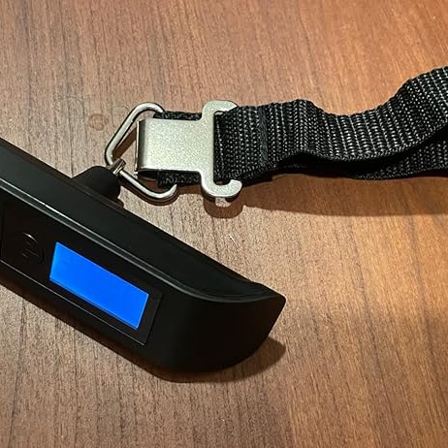

In [ ]:
conversations[0][0]['_preprocessed_image']

## Run LLM for Image Summary

In [ ]:
# 설정
batch_size = 2
save_interval = 1000
save_dir = "/content/drive/MyDrive/MLLM_output/Fashion_Chunk_7"
os.makedirs(save_dir, exist_ok=True)

total_len = len(prompts)
all_summaries = [None] * total_len  # 전체 결과 저장소
chunk_index = 60

# === 배치 실행 ===
for i in tqdm(range(0, total_len, batch_size)):
    batch_convs = conversations[i: i + batch_size]
    batch_prompts = prompts[i: i + batch_size]

    batch_images = []
    valid_prompts = []
    valid_indices = []

    # 이미지 및 인덱스 필터링
    for j, conv in enumerate(batch_convs):
        img = conv[0].get("_preprocessed_image")
        global_idx = i + j

        if isinstance(img, Image.Image):
            batch_images.append(img)
            valid_prompts.append(batch_prompts[j])
            valid_indices.append(global_idx)
        else:
            print(f"[⚠️ Skipped] Invalid image at index {global_idx}")
            all_summaries[global_idx] = "[INVALID IMAGE]"

    if not batch_images:
        print(f"[⛔] Skipping batch starting at {i} (all images invalid)")
        continue

    # LLM 입력 준비
    batch_inputs = processor(
        images=batch_images,
        text=valid_prompts,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to("cuda:0")

    # 모델 출력 생성
    output_ids = model.generate(
        **batch_inputs,
        max_new_tokens=256,
        pad_token_id=processor.tokenizer.pad_token_id
    )
    decoded_batch = [processor.decode(ids, skip_special_tokens=True) for ids in output_ids]

    # 출력 결과 저장
    for idx, summary in zip(valid_indices, decoded_batch):
        all_summaries[idx] = extract_response_text_llava(summary)

    # === 청크 저장 조건 확인 ===
    filled_indices = [idx for idx, val in enumerate(all_summaries) if val is not None]
    if len(filled_indices) >= save_interval:
        chunk_data = []
        saved_indices = []
        for idx in filled_indices[:save_interval]:
            chunk_data.append(all_summaries[idx])
            saved_indices.append(idx)

        save_chunk(chunk_data, chunk_index, save_dir)

        # 저장한 결과는 초기화
        for idx in saved_indices:
            all_summaries[idx] = None

        chunk_index += 1

# === 마지막 남은 결과 저장 ===
valid_remaining = [val for val in all_summaries if val is not None]
if valid_remaining:
    remaining_to_save = [val if val is not None else "[INVALID IMAGE]" for val in all_summaries]
    save_chunk(remaining_to_save, chunk_index, save_dir)

 15%|█▍        | 500/3359 [1:39:22<9:48:17, 12.35s/it]

✅ Saved: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_060.json (1000 samples)


 30%|██▉       | 1000/3359 [3:20:10<8:36:57, 13.15s/it]

✅ Saved: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_061.json (1000 samples)


 45%|████▍     | 1500/3359 [5:01:38<6:19:16, 12.24s/it]

✅ Saved: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_062.json (1000 samples)


... (4 outputs left out)

 89%|████████▉ | 3000/3359 [9:59:37<1:09:47, 11.67s/it]

✅ Saved: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_065.json (1000 samples)


100%|██████████| 3359/3359 [11:11:29<00:00, 11.99s/it]

✅ Saved: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_066.json (6718 samples)


# Concat Dataset and Chunk

In [ ]:
import json

# 파일 경로
input_path = "/content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_066.json"
output_path = "/content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_066_cleaned.json"

# 1. 파일 읽기
with open(input_path, "r", encoding="utf-8") as f:
    data = json.load(f)

# 2. "[INVALID]" 항목 제거
cleaned_data = [entry for entry in data if entry.strip() != "[INVALID IMAGE]"]

# 3. 다시 저장
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(cleaned_data, f, ensure_ascii=False, indent=4)

print(f"✅ 저장 완료: {output_path} (원래 {len(data)}개 → {len(cleaned_data)}개)")

✅ 저장 완료: /content/drive/MyDrive/MLLM_output/Fashion_Chunk_7/aspect_summary_chunk_066_cleaned.json (원래 6718개 → 718개)


In [ ]:
# 디렉토리 경로 설정
load_dir = "/content/drive/MyDrive/MLLM_output/Fashion_Chunk_7"

# 파일 이름 정렬
file_names = sorted([
    f for f in os.listdir(load_dir) if f.startswith("aspect_summary_chunk_") and f.endswith(".json")
])

# 파일 읽기 및 DataFrame으로 로드
df_list = []
for file_name in file_names:
    file_path = os.path.join(load_dir, file_name)
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
        text_df = pd.DataFrame(data)
        df_list.append(text_df)

# axis=0 방향으로 합치기 (행 방향)
combined_df = pd.concat(df_list, axis=0, ignore_index=True)

# 결과 확인 (옵션)
print(f"총 샘플 수: {len(combined_df)}")
print(combined_df.head())

총 샘플 수: 6718
                                                   0
0  The image shows a portable digital luggage sca...
1  The image shows a set of eight luggage tags, e...
2  The image shows a piece of jewelry, specifical...
3  The image shows a set of small gold hoop earri...
4  The image shows a pair of sunglasses with a wo...


In [ ]:
combined_df.columns = ['LLaVA_Output']
df = pd.concat([df, combined_df], axis=1)

In [ ]:
pd.set_option('display.max_colwidth', None)

df[['title_y', 'LLaVA_Output']].tail(20)

In [ ]:
df.to_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b7.pkl')

In [ ]:
img1 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b1.pkl')
img2 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b2.pkl')
img3 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b3.pkl')
img4 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b4.pkl')
img5 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b5.pkl')
img6 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b6.pkl')
img7 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_img_b7.pkl')

img_last = pd.concat([img1, img2, img3, img4, img5, img6, img7], axis=0)

print(img_last.shape)

(66718, 16)


In [ ]:
text1 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b1.pkl')
text2 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b2.pkl')
text3 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b3.pkl')
text4 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b4.pkl')
text5 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b5.pkl')
text6 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b6.pkl')
text7 = pd.read_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_review_b7.pkl')

text_last = pd.concat([text1, text2, text3, text4, text5, text6, text7], axis=0)
print(text_last.shape)

(66718, 16)


In [ ]:
text_last = text_last.reset_index(drop=True)
img_last = img_last.reset_index(drop=True)

In [ ]:
img_last.index

RangeIndex(start=0, stop=66718, step=1)

In [ ]:
llava = img_last[['LLaVA_Output']]

final = pd.concat([text_last, llava], axis=1)

In [ ]:
pd.set_option('display.max_colwidth', None)

final[['title_y', 'LLaMA_Output', 'LLaVA_Output']].tail(20)

In [ ]:
final.to_pickle('/content/drive/MyDrive/Clothing_Shoes_v5_final.pkl')
final.to_json('/content/drive/MyDrive/Clothing_Shoes_v5_final.json')